# IND320, Assignment 3
## By: Ole Andreas Grøtting
Github: [IND320 - OLEGRO99](https://github.com/olegro99/IND320-OLEGRO99.git)\
Streamlit: https://ind320-olegro99-ybwpxf3ssrwyekrthttcuc.streamlit.app/

# Work log
I started the project by collecting the necessary data from the different sources, including weather data and energy related data. An important first step was to check the time zones used by the different APIs. Since the datasets used different time zones, I had to convert them into a consistent format to ensure that the observations matched correctly. This was important when combining the datasets and preparing them for further analysis.

After preparing the data, I started working on the machine learning part of the assignment. I initially developed a lag-based machine learning model. Through trial and error, I tested different lag lengths and combinations of variables to improve the model's performance. I also experimented with a SARIMAX model. The SARIMAX model achieved better results than my initial lag-based approach, so I decided to use it as the main forecasting model for this assignment. I continued testing different configurations and variables to identify the combination that provided the best performance. I also tested this using the corrolation page.

In addition to the forecasting experiments, I explored the correlation page in the Streamlit application. This allowed me to investigate the relationship between meteorological variables and reservoir filling. I tested different weather variables, time lags and window lengths to see how the correlations changed over time. I have included comments and observations about these experiments in the machine learning section of this notebook.

After completing much of the analysis, I started developing the interactive map in the Streamlit application. This was one of the most challenging parts of the project. I struggled with getting the geographical data, regional boundaries and map layers to work correctly. I used the lectures as inspiration and guidance, together with AI assistance, to understand the problems and find solutions. I also experienced some difficulties with the Open-Meteo API, particularly when downloading weather data for a large number of geographical points. Due to API request limitations, I had to reduce the number of points per region to 20. This made it possible to display the map and its weather information during the screencast.

For the forecasting functionality in Streamlit, I implemented the SARIMAX model that I had developed and evaluated in the notebook. I used the variables and configurations that performed best during the earlier experiments, allowing the application to present forecasts based on the results from the analysis.

Finally, I selected the error-handling task as my additional bonus task for the Streamlit application. I implemented checks to handle API failures, empty datasets and missing values (NaN). Instead of allowing the application to crash when something went wrong, it now displays informative error and warning messages. This improves the robustness and user experience of the application.

# Usage of AI
i have used AI to:
- Grammar and language: Used AI to improve grammar, spelling and the wording of explanations.
- Understanding code: Used AI to explain methods that I was unfamiliar with.
- Debugging: Used AI to identify and solve errors in Python code, particularly when working with the Streamlit application.
- Machine learning: Used AI to understand different modelling approaches, troubleshoot code and compare forecasting methods such as lag-based models and SARIMAX.
- Interactive map: Used AI for guidance on implementing GeoJSON data, geographical boundaries and coloured map layers.

## imports

In [19]:
import time
import tomllib
from itertools import product

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from entsoe import EntsoePandasClient

from river import time_series, linear_model, optim, preprocessing, metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error

# downloading data

In [2]:
def download_exchange_rates(start_date, end_date):

    # Define the Norges Bank API URL for EUR and USD exchange rates against NOK
    url = (
        "https://data.norges-bank.no/api/data/EXR/"
        "B.EUR+USD.NOK.SP"
        f"?format=csv&startPeriod={start_date}"
        f"&endPeriod={end_date}"
        "&locale=en&bom=include"
    )

    # Send a GET request to the API
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    # Read the CSV response into a pandas DataFrame
    exchange_rates = pd.read_csv(
        pd.io.common.StringIO(response.text),
        sep=";"
    )

    # Return the exchange rate data
    return exchange_rates

In [3]:
# Download EUR and USD exchange rates for the selected period
exchange_rates_df = download_exchange_rates(
    start_date="2024-10-15",
    end_date="2026-10-14"
)

# Display the first rows of the dataset
print(exchange_rates_df.head())

# Display the column names
print(exchange_rates_df.columns)

# Check the number of observations
print("Number of observations:", len(exchange_rates_df))

  FREQ Frequency BASE_CUR Base Currency QUOTE_CUR   Quote Currency TENOR  \
0    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
1    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
2    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
3    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
4    B  Business      USD     US dollar       NOK  Norwegian krone    SP   

  Tenor  DECIMALS  CALCULATED  UNIT_MULT Unit Multiplier COLLECTION  \
0  Spot         4       False          0           Units          C   
1  Spot         4       False          0           Units          C   
2  Spot         4       False          0           Units          C   
3  Spot         4       False          0           Units          C   
4  Spot         4       False          0           Units          C   

              Collection Indicator TIME_PERIOD  OBS_VALUE  
0  ECB concertation time 14:15 CET  2024-10-15    10.791

## checking time zones

In [4]:
def download_nve_data():

    # Define the NVE API URL for reservoir statistics
    url = (
        "https://biapi.nve.no/magasinstatistikk/"
        "api/Magasinstatistikk/HentOffentligData"
    )

    # Send a GET request to the API
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    # Convert the JSON response into a pandas DataFrame
    data = response.json()
    nve_df = pd.DataFrame(data)

    # Remove invalid publication dates
    nve_df = nve_df[
        nve_df["neste_Publiseringsdato"] != "0001-01-01T00:00:00"
    ].copy()

    # Convert the date column to datetime format
    nve_df["dato_Id"] = pd.to_datetime(nve_df["dato_Id"])

    # Return the cleaned reservoir data
    return nve_df


# Download reservoir data from the NVE API
df = download_nve_data()

# Display the first rows of the dataset
print(df.head())

# Summarize observations and date ranges for each reservoir area
print(
    df.groupby(["omrType", "omrnr"])
    .agg(
        observations=("fyllingsgrad", "count"),
        start_date=("dato_Id", "min"),
        end_date=("dato_Id", "max")
    )
)

      dato_Id omrType  omrnr  iso_aar  iso_uke  fyllingsgrad  kapasitet_TWh  \
0  2020-11-15      EL      1     2020       46      0.974361       6.003264   
7  2023-08-13      EL      5     2023       32      0.836849      17.390587   
10 2021-04-18      EL      5     2021       15      0.246682      17.390587   
11 2019-06-02      EL      1     2019       22      0.659981       6.003264   
13 2019-10-27      EL      1     2019       43      0.896057       6.003264   

    fylling_TWh neste_Publiseringsdato  fyllingsgrad_forrige_uke  \
0      5.849344    2020-11-25T13:00:00                  0.997406   
7     14.553301    2023-08-23T13:00:00                  0.776765   
10     4.289936    2021-04-28T13:00:00                  0.276825   
11     3.962040    2019-06-12T13:00:00                  0.625398   
13     5.379270    2019-11-06T13:00:00                  0.882742   

    endring_fyllingsgrad  
0              -0.023046  
7               0.060084  
10             -0.030144  
11      

In [5]:
# Checking timezone for Norges Bank
nb_dates = pd.to_datetime(exchange_rates_df["TIME_PERIOD"])

print(nb_dates.head())
print(nb_dates.dtype)
print(nb_dates.dt.tz)

# Check whether timestamps contain a time component
print(nb_dates.dt.strftime("%Y-%m-%d %H:%M:%S").head())

0   2024-10-15
1   2024-10-16
2   2024-10-17
3   2024-10-18
4   2024-10-21
Name: TIME_PERIOD, dtype: datetime64[us]
datetime64[us]
None
0    2024-10-15 00:00:00
1    2024-10-16 00:00:00
2    2024-10-17 00:00:00
3    2024-10-18 00:00:00
4    2024-10-21 00:00:00
Name: TIME_PERIOD, dtype: str


In [6]:
def download_entsoe_data(start_date, end_date, api_key):

    # Initialize the ENTSO-E API client
    client = EntsoePandasClient(api_key=api_key)

    # Define the start and end dates in UTC
    start = pd.Timestamp(start_date, tz="UTC")
    end = pd.Timestamp(end_date, tz="UTC")

    # Download cross-border electricity flow data from NO_2 to DK_1
    flows = client.query_crossborder_flows(
        country_code_from="NO_2",
        country_code_to="DK_1",
        start=start,
        end=end
    )

    # Convert the returned time series into a DataFrame
    flows_df = flows.rename("flow_mw").to_frame()

    # Return the electricity flow data
    return flows_df


# Load the ENTSO-E API key from secrets.toml
with open("../streamlit app/.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

# Download cross-border electricity flow data for the selected period
flows_df = download_entsoe_data(
    start_date="2024-10-15",
    end_date="2026-10-15",
    api_key=secrets["ENTSOE_API_KEY"]
)

# Display the first rows and dimensions of the dataset
print(flows_df.head())
print(flows_df.shape)

                           flow_mw
2024-10-15 02:00:00+02:00  1386.84
2024-10-15 03:00:00+02:00  1386.69
2024-10-15 04:00:00+02:00  1386.92
2024-10-15 05:00:00+02:00  1387.20
2024-10-15 06:00:00+02:00  1387.27
(57480, 1)


In [7]:
def download_weather_data(start_date, end_date):

    # Define the Open-Meteo historical weather API URL
    url = "https://archive-api.open-meteo.com/v1/archive"

    # Set the location, date range and weather variables to download
    params = {
        "latitude": 59.66,
        "longitude": 10.78,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": [
            "temperature_2m",
            "precipitation",
            "relative_humidity_2m",
            "wind_speed_10m"
        ],
        "timezone": "GMT"
    }

    # Send a GET request to the API
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    # Convert the JSON response into a pandas DataFrame
    weather_data = response.json()
    weather_df = pd.DataFrame(weather_data["hourly"])

    # Convert timestamps to UTC datetime format
    weather_df["time"] = pd.to_datetime(
        weather_df["time"],
        utc=True
    )

    # Set the timestamp as the DataFrame index
    weather_df = weather_df.set_index("time")

    # Return the weather data
    return weather_df


# Download historical weather data for the selected period
weather_df = download_weather_data(
    start_date="2024-10-15",
    end_date="2026-10-14"
)

# Display the first rows and dimensions of the dataset
print(weather_df.head())
print(weather_df.shape)

                           temperature_2m  precipitation  \
time                                                       
2024-10-15 00:00:00+00:00             1.2            0.0   
2024-10-15 01:00:00+00:00             0.9            0.0   
2024-10-15 02:00:00+00:00             0.5            0.0   
2024-10-15 03:00:00+00:00             0.5            0.0   
2024-10-15 04:00:00+00:00             1.5            0.0   

                           relative_humidity_2m  wind_speed_10m  
time                                                             
2024-10-15 00:00:00+00:00                    86             8.4  
2024-10-15 01:00:00+00:00                    87             7.7  
2024-10-15 02:00:00+00:00                    86             9.1  
2024-10-15 03:00:00+00:00                    85             8.3  
2024-10-15 04:00:00+00:00                    82             5.8  
(17520, 4)


The four data sources have different temporal resolutions. NVE Magasinstatistikk contains multiple observations per date, with weekly intervals between some dates. ENTSO-E mainly provides data at 15-minute intervals, while Open-Meteo provides hourly observations. Norges Bank provides daily exchange rates on business days, resulting in gaps during weekends and holidays.

Regarding time zones, ENTSO-E and Open-Meteo timestamps are represented in UTC. NVE and Norges Bank contain timezone-naive timestamps, meaning that no explicit timezone information is provided. Therefore, the original dates were retained rather than assigning an assumed timezone. This avoids introducing unnecessary timezone conversions.

An initial comparison of ENTSO-E and Open-Meteo timestamps resulted in zero matching timestamps. This was not caused by a timezone difference, but because the datasets covered different periods. ENTSO-E covered October 2024 to October 2026, while the downloaded Open-Meteo data covered 2023.

To combine the data sources, their temporal resolutions must be aligned. ENTSO-E can be aggregated from 15-minute to hourly observations, while Open-Meteo is already hourly. For the forecasting model, the datasets can then be aggregated to monthly frequency. NVE observations can be represented by monthly averages, while Norges Bank exchange rates can also be aggregated to monthly averages.

In [8]:
def prepare_nve_data(nve_df, area_number=1):

    # Select reservoir data for the specified electricity price area
    region_data = nve_df[
        (nve_df["omrType"] == "EL") &
        (nve_df["omrnr"] == area_number)
    ].copy()

    # Aggregate reservoir data into monthly averages
    monthly = (
        region_data
        .set_index("dato_Id")
        [["fyllingsgrad", "fylling_TWh", "kapasitet_TWh"]]
        .resample("MS")
        .mean()
        .dropna()
    )

    # Remove potentially incomplete first and last months
    monthly = monthly.iloc[1:-1].copy()

    # Return the prepared monthly dataset
    return monthly


# Prepare monthly reservoir data for electricity price area NO1
monthly_data = prepare_nve_data(df, area_number=1)

# Display the first rows and dimensions of the dataset
print(monthly_data.head())
print(monthly_data.shape)

            fyllingsgrad  fylling_TWh  kapasitet_TWh
dato_Id                                             
2019-03-01      0.204981     1.230556       6.003264
2019-04-01      0.155148     0.931395       6.003264
2019-05-01      0.452889     2.718814       6.003264
2019-06-01      0.766273     4.600138       6.003264
2019-07-01      0.800576     4.806070       6.003264
(92, 3)


In [30]:
# IKKE kjør prepare_nve_data() igjen på denne - den er allerede prepared
nve_monthly = monthly_data  # direkte tilordning, ingen reprosessering

# Sanity check
print(nve_monthly.shape)
print(nve_monthly.columns.tolist())
print(nve_monthly.index.min(), "→", nve_monthly.index.max())

(92, 3)
['fyllingsgrad', 'fylling_TWh', 'kapasitet_TWh']
2019-03-01 00:00:00 → 2026-10-01 00:00:00


In [9]:
# Aggregate hourly electricity flows into monthly averages
entsoe_monthly = (
    flows_df
    .resample("MS")
    .mean()
)

# Remove timezone information after aggregation in UTC
entsoe_monthly.index = entsoe_monthly.index.tz_localize(None)

In [10]:
# Aggregate hourly weather data into monthly values
weather_monthly = weather_df.resample("MS").agg({
    "temperature_2m": "mean",
    "precipitation": "sum",
    "relative_humidity_2m": "mean",
    "wind_speed_10m": "mean"
})

# Remove timezone information after aggregation in UTC
weather_monthly.index = weather_monthly.index.tz_localize(None)

print(exchange_rates_df.columns.tolist())
print(exchange_rates_df.head())

['FREQ', 'Frequency', 'BASE_CUR', 'Base Currency', 'QUOTE_CUR', 'Quote Currency', 'TENOR', 'Tenor', 'DECIMALS', 'CALCULATED', 'UNIT_MULT', 'Unit Multiplier', 'COLLECTION', 'Collection Indicator', 'TIME_PERIOD', 'OBS_VALUE']
  FREQ Frequency BASE_CUR Base Currency QUOTE_CUR   Quote Currency TENOR  \
0    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
1    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
2    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
3    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
4    B  Business      USD     US dollar       NOK  Norwegian krone    SP   

  Tenor  DECIMALS  CALCULATED  UNIT_MULT Unit Multiplier COLLECTION  \
0  Spot         4       False          0           Units          C   
1  Spot         4       False          0           Units          C   
2  Spot         4       False          0           Units          C   
3  Spot         4       False      

In [11]:
# Create an overview of time zones before and after monthly aggregation
timezone_overview = pd.DataFrame({
    "Data source": [
        "NVE",
        "ENTSO-E",
        "Open-Meteo",
        "Norges Bank"
    ],
    "Original timezone": [
        str(df["dato_Id"].dt.tz),  # Time zone of the original NVE timestamps
        str(flows_df.index.tz),  # Time zone of the original ENTSO-E timestamps
        str(weather_df.index.tz),  # Time zone of the original Open-Meteo timestamps
        str(pd.to_datetime(exchange_rates_df["TIME_PERIOD"]).dt.tz)  # Time zone of the original exchange rate timestamps
    ],
    "Monthly timezone": [
        str(monthly_data.index.tz),  # Time zone after monthly aggregation
        str(entsoe_monthly.index.tz),  # Time zone after monthly aggregation
        str(weather_monthly.index.tz),  # Time zone after monthly aggregation
        "Not yet aggregated"  # Norges Bank data has not been aggregated yet
    ]
})

# Display the time zone overview
print(timezone_overview)

   Data source Original timezone    Monthly timezone
0          NVE              None                None
1      ENTSO-E       Europe/Oslo                None
2   Open-Meteo               UTC                None
3  Norges Bank              None  Not yet aggregated


In [12]:
# Combine the monthly datasets using their common dates
combined_data = (
    monthly_data
    .join(weather_monthly, how="inner")  # Join NVE and weather data using matching dates
    .join(entsoe_monthly, how="inner")  # Add ENTSO-E data using matching dates
)

# Keep only complete months within the selected study period
combined_data = combined_data.loc[
    "2024-11-01":"2026-09-01"  # Select months from November 2024 to September 2026
].dropna()  # Remove rows containing missing values

# Display information about the combined dataset
print("Number of observations:", len(combined_data))  # Number of complete monthly observations
print("Start:", combined_data.index.min())  # First month in the dataset
print("End:", combined_data.index.max())  # Last month in the dataset
print(combined_data.head())  # Display the first five observations
print(combined_data.isna().sum())  # Check for missing values in each column

Number of observations: 23
Start: 2024-11-01 00:00:00
End: 2026-09-01 00:00:00
            fyllingsgrad  fylling_TWh  kapasitet_TWh  temperature_2m  \
dato_Id                                                                
2024-11-01      0.924905     5.552451       6.003264        1.992500   
2024-12-01      0.803228     4.821990       6.003264        0.355645   
2025-01-01      0.663941     3.985812       6.003264       -3.171909   
2025-02-01      0.486722     2.921918       6.003264       -2.794643   
2025-03-01      0.320056     1.921381       6.003264        3.336559   

            precipitation  relative_humidity_2m  wind_speed_10m      flow_mw  
dato_Id                                                                       
2024-11-01           35.2             84.518056        9.362083  1085.276403  
2024-12-01           64.5             87.009409       11.639382  1035.045941  
2025-01-01          110.4             88.946237        9.851747  1022.086841  
2025-02-01           

In [13]:
exchange_rates_df["TIME_PERIOD"] = pd.to_datetime(exchange_rates_df["TIME_PERIOD"])

# Separate EUR og USD kurser, resample til månedlig snitt
eur_monthly = (
    exchange_rates_df[exchange_rates_df["BASE_CUR"] == "EUR"]
    .set_index("TIME_PERIOD")["OBS_VALUE"]
    .resample("MS").mean()
    .rename("eur_nok")
)

usd_monthly = (
    exchange_rates_df[exchange_rates_df["BASE_CUR"] == "USD"]
    .set_index("TIME_PERIOD")["OBS_VALUE"]
    .resample("MS").mean()
    .rename("usd_nok")
)

combined_data = combined_data.join(eur_monthly).join(usd_monthly)

In [15]:
# Fjern eur_nok/usd_nok hvis de allerede finnes (gjør cellen trygg å kjøre flere ganger)
combined_data = combined_data.drop(columns=["eur_nok", "usd_nok"], errors="ignore")

combined_data = combined_data.join(eur_monthly).join(usd_monthly)
combined_data = combined_data.dropna()
print(combined_data.shape)

(23, 10)


In [31]:
overlap = nve_monthly.index.intersection(combined_data.index)
print(f"Overlappende måneder: {len(overlap)} av {len(nve_monthly)} totalt i nve_monthly")
print(f"Overlapp-periode: {overlap.min()} → {overlap.max()}" if len(overlap) > 0 else "Ingen overlapp!")

Overlappende måneder: 23 av 92 totalt i nve_monthly
Overlapp-periode: 2024-11-01 00:00:00 → 2026-09-01 00:00:00


The four data sources have different temporal resolutions. NVE Magasinstatistikk contains multiple observations per date, with weekly intervals between some dates. ENTSO-E provides data at 15-minute to hourly resolution (in this project aggregated directly to monthly means), while Open-Meteo provides hourly observations. Norges Bank provides daily reference exchange rates on business days (fixed at 14:15 CET), resulting in gaps during weekends and holidays.

Regarding time zones, Open-Meteo timestamps are UTC-aware, while ENTSO-E timestamps are originally represented in Europe/Oslo local time. NVE and Norges Bank contain timezone-naive timestamps, meaning no explicit timezone information is provided. For NVE and NB, the original naive dates were retained rather than assigning an assumed timezone, since doing so would introduce an unverifiable assumption rather than genuine information.

Since ENTSO-E (Oslo) and Open-Meteo (UTC) are in different timezones, true alignment would require converting one series to match the other before aggregation. In this project, timezone information was instead removed after monthly aggregation (rather than converted), which is a simplification: monthly boundaries for ENTSO-E reflect Oslo local time, while monthly boundaries for Open-Meteo reflect UTC. Given that Oslo time differs from UTC by only 1–2 hours, the effect on monthly aggregates is expected to be minor, but it is acknowledged as a limitation rather than a fully resolved alignment.

To combine the data sources, temporal resolutions were aligned by aggregating all series to monthly frequency: ENTSO-E and Open-Meteo hourly/sub-hourly data to monthly means (and monthly sums for precipitation), NVE observations to monthly averages, and Norges Bank exchange rates to monthly averages of the daily 14:15 CET reference rate.

## machine learning - SARIMAX

In [52]:
import time
from river import metrics


def backtest_snarimax(
    nve_monthly: pd.DataFrame,
    exogenous_data: pd.DataFrame | None = None,
    target_col: str = "fyllingsgrad",
    exogenous_cols: list[str] | None = None,
    history_months: int = 36,
    horizon_months: int = 3,
    param_grid: list[dict] | None = None,
    n_folds: int = 5,
) -> pd.DataFrame:
    """
    Walk-forward backtesting av SNARIMAX for ulike parametersett.

    For hvert fold trenes modellen på `history_months` måneder som ender
    ved et "cutoff"-tidspunkt, og prognosen for de neste `horizon_months`
    måneder sammenlignes med faktiske observerte verdier (MAE/RMSE).
    Cutoff flyttes fremover for hvert fold (n_folds stk, jevnt fordelt).

    NB: I backtesten brukes de *faktiske* fremtidige eksogene verdiene
    (perfekt informasjon) for å isolere modellens egen prediksjonsevne —
    dette er optimistisk sammenlignet med reell drift, hvor fremtidige
    eksogene verdier er ukjente.

    Returns
    -------
    pd.DataFrame med én rad per (parametersett, fold): MAE, RMSE, kjøretid.
    """
    exogenous_cols = exogenous_cols or []

    merged = nve_monthly[[target_col]].copy()
    if exogenous_cols:
        merged = merged.join(exogenous_data[exogenous_cols], how="inner")
    merged = merged.sort_index().dropna()

    if param_grid is None:
        param_grid = [
            dict(p=1, d=0, q=0, m=12, sp=0, sd=0, sq=0),
            dict(p=1, d=0, q=1, m=12, sp=1, sd=0, sq=0),
            dict(p=2, d=0, q=1, m=12, sp=1, sd=0, sq=0),
            dict(p=2, d=1, q=1, m=12, sp=1, sd=0, sq=1),
        ]

    min_start = history_months
    max_start = len(merged) - horizon_months
    if max_start <= min_start:
        raise ValueError("Ikke nok data til valgt history_months + horizon_months.")

    cutoffs = np.linspace(min_start, max_start, n_folds, dtype=int)
    results = []

    for params in param_grid:
        for cutoff in cutoffs:
            train = merged.iloc[cutoff - history_months: cutoff]
            test = merged.iloc[cutoff: cutoff + horizon_months]
            if len(test) < horizon_months:
                continue

            t0 = time.time()
            regressor = (
                preprocessing.StandardScaler()
                | linear_model.LinearRegression(optimizer=optim.SGD(0.01))
            )
            model = time_series.SNARIMAX(regressor=regressor, **params)

            for _, row in train.iterrows():
                y = row[target_col]
                x = row[exogenous_cols].to_dict() if exogenous_cols else None
                model.learn_one(y=y, x=x)

            xs = test[exogenous_cols].to_dict("records") if exogenous_cols else None
            preds = model.forecast(horizon=horizon_months, xs=xs)
            runtime = time.time() - t0

            mae, rmse = metrics.MAE(), metrics.RMSE()
            for y_true, y_pred in zip(test[target_col], preds):
                mae.update(y_true, y_pred)
                rmse.update(y_true, y_pred)

            results.append({
                **params,
                "history_months": history_months,
                "horizon_months": horizon_months,
                "cutoff_date": merged.index[cutoff],
                "mae": mae.get(),
                "rmse": rmse.get(),
                "runtime_sec": runtime,
            })

    return pd.DataFrame(results)

In [70]:
param_grid = [
    # Modell 1: Enkel AR-modell
    dict(p=1, d=0, q=0, m=12, sp=0, sd=0, sq=0),

    # Modell 2: ARMA med sesongkomponent
    dict(p=1, d=0, q=1, m=12, sp=1, sd=0, sq=0),

    # Modell 3: Mer kompleks ARMA
    dict(p=2, d=0, q=1, m=12, sp=1, sd=0, sq=0),

    # Modell 4: Differensiert modell med sesongbasert MA
    dict(p=2, d=1, q=1, m=12, sp=1, sd=0, sq=1),

    # Modell 5: AR-modell med differensiering
    dict(p=1, d=1, q=0, m=12, sp=0, sd=0, sq=0),

    # Modell 6: ARMA med differensiering
    dict(p=1, d=1, q=1, m=12, sp=0, sd=0, sq=0),
]

In [77]:
overlap_data = nve_monthly.loc[overlap]

test_a_params = dict(
    target_col="fyllingsgrad",
    history_months=12,
    horizon_months=6,
    n_folds=3,
    param_grid=param_grid
)

# Test uten eksogene variabler
results_a_no_exo = backtest_snarimax(
    overlap_data,
    **test_a_params
)

# Test med eksogene variabler
results_a_with_exo = backtest_snarimax(
    overlap_data,
    exogenous_data=combined_data,
    exogenous_cols=["eur_nok", "usd_nok"],
    **test_a_params
)

print("=== Test A: Samme periode ===")
print("Uten eksogene:\n", results_a_no_exo)
print("Med eksogene:\n", results_a_with_exo)

=== Test A: Samme periode ===
Uten eksogene:
     p  d  q   m  sp  sd  sq  history_months  horizon_months cutoff_date  \
0   1  0  0  12   0   0   0              12               6  2025-11-01   
1   1  0  0  12   0   0   0              12               6  2026-01-01   
2   1  0  0  12   0   0   0              12               6  2026-04-01   
3   1  0  1  12   1   0   0              12               6  2025-11-01   
4   1  0  1  12   1   0   0              12               6  2026-01-01   
5   1  0  1  12   1   0   0              12               6  2026-04-01   
6   2  0  1  12   1   0   0              12               6  2025-11-01   
7   2  0  1  12   1   0   0              12               6  2026-01-01   
8   2  0  1  12   1   0   0              12               6  2026-04-01   
9   2  1  1  12   1   0   1              12               6  2025-11-01   
10  2  1  1  12   1   0   1              12               6  2026-01-01   
11  2  1  1  12   1   0   1              12           

In [42]:
results_a_no_exo["data_source"] = "Without exogenous"
results_a_with_exo["data_source"] = "With exogenous"

all_results = pd.concat(
    [results_a_no_exo, results_a_with_exo],
    ignore_index=True
)

comparison = (
    all_results
    .groupby(
        ["data_source", "p", "d", "q", "sp", "sd", "sq"]
    )[["mae", "rmse", "runtime_sec"]]
    .mean()
    .reset_index()
    .sort_values("mae")
)

print(comparison.to_string(index=False))

      data_source  p  d  q  sp  sd  sq      mae     rmse  runtime_sec
Without exogenous  1  1  0   0   0   0 0.103006 0.124056     0.000552
   With exogenous  1  1  0   0   0   0 0.116017 0.132475     0.004726
Without exogenous  1  1  1   0   0   0 0.130372 0.147199     0.000537
   With exogenous  1  1  1   0   0   0 0.136439 0.156002     0.004846
Without exogenous  2  1  1   1   0   1 0.156700 0.175489     0.000540
   With exogenous  2  1  1   1   0   1 0.160836 0.195987     0.005040
   With exogenous  1  0  0   0   0   0 0.409113 0.423402     0.006435
   With exogenous  1  0  1   1   0   0 0.497974 0.521162     0.005735
   With exogenous  2  0  1   1   0   0 0.511162 0.548800     0.005321
Without exogenous  1  0  0   0   0   0 0.554204 0.573254     0.000703
Without exogenous  2  0  1   1   0   0 0.629181 0.678309     0.000546
Without exogenous  1  0  1   1   0   0 0.631879 0.664069     0.000528


In [62]:
best_param_grid = [
    # Beste modell
    dict(p=1, d=1, q=0, m=12, sp=0, sd=0, sq=0),

    # Nest beste modell
    dict(p=1, d=1, q=1, m=12, sp=0, sd=0, sq=0),
]

In [79]:
history_lengths = [12, 15, 18]

history_results = []

for history in history_lengths:

    test_params = dict(
        target_col="fyllingsgrad",
        history_months=history,
        horizon_months=3,
        n_folds=3,
        param_grid=best_param_grid
    )

    result = backtest_snarimax(
        overlap_data,
        **test_params
    )

    result["history_months"] = history
    history_results.append(result)


history_comparison = pd.concat(
    history_results,
    ignore_index=True
)

print(
    history_comparison
    .groupby(["history_months", "p", "d", "q"])[
        ["mae", "rmse", "runtime_sec"]
    ]
    .mean()
    .sort_values("mae")
)

                           mae      rmse  runtime_sec
history_months p d q                                 
12             1 1 0  0.103006  0.124056     0.000784
                   1  0.130372  0.147199     0.000560
15             1 1 0  0.190857  0.220300     0.000622
                   1  0.206857  0.238104     0.000586
18             1 1 1  0.266817  0.277542     0.001092
                   0  0.274703  0.286148     0.000809


### Effect of historical window length and correlation stability

The effect of historical window length was investigated using 12, 15 and 18 months of training data. Two model configurations, ARIMA(1,1,0) and ARIMA(1,1,1), were compared.

The results showed that 12 months of historical data provided the best forecasting accuracy. The ARIMA(1,1,0) model achieved an MAE of 0.1030 and an RMSE of 0.1241. Increasing the historical window to 15 and 18 months resulted in higher forecasting errors. This may indicate that older observations are less representative of recent reservoir filling patterns.

In addition to the forecasting experiments, the Sliding Window Correlation analysis in the Streamlit application was used to investigate the relationship between meteorological variables and reservoir filling levels. The results indicated that correlation stability was most promising around a 12-week historical window/lag. This is particularly interesting because a stable correlation over time may be more informative than simply obtaining a high peak correlation at a specific point.

One possible physical explanation for a delayed relationship between temperature and reservoir filling is snowmelt. Higher temperatures can accelerate snowmelt, increasing water inflow into reservoirs. Depending on catchment characteristics, this process may take several weeks before its effect becomes visible in reservoir filling levels. A delay of approximately 12 weeks could therefore be worth investigating further.

Both temperature and reservoir filling levels are influenced by seasonal patterns, which can produce spurious correlations. Furthermore, correlation does not establish causation. Investigating whether the relationship remains stable across different years and seasons, and comparing it with other meteorological variables and lag values, would provide stronger evidence of a potentially meaningful relationship.

Overall, the preliminary results suggest that a 12-month training window was the most promising choice for the ARIMA forecasting models, while the correlation analysis highlighted an interesting potential delayed relationship between meteorological conditions and reservoir filling. Both findings require further validation using additional time periods.

In [61]:
DEFAULT_FORECAST_SETTINGS = {
    "history_months": 12,
    "horizon_months": 9,
    "p": 1,
    "d": 1,
    "q": 0,
    "m": 12,
    "sp": 0,
    "sd": 0,
    "sq": 0,
    "exogenous_cols": None,
}

In [80]:
from river import time_series, preprocessing, linear_model, optim
import pandas as pd


def forecast_reservoir_filling(
    monthly_data,
    target_col="fyllingsgrad",
    history_months=12,
    horizon_months=6,
    p=1,
    d=1,
    q=0,
    m=12,
    sp=0,
    sd=0,
    sq=0,
):
    """
    Forecast reservoir filling for one NVE region.

    Uses a River SNARIMAX model trained on monthly observations.
    """

    # Select target and remove missing observations
    data = monthly_data[[target_col]].copy()
    data = data.sort_index().dropna()

    # Use only the most recent observations
    train_data = data.tail(history_months)

    if len(train_data) < history_months:
        raise ValueError(
            "Not enough historical observations for the selected history length."
        )

    # Create the SNARIMAX model
    model = time_series.SNARIMAX(
        p=p,
        d=d,
        q=q,
        m=m,
        sp=sp,
        sd=sd,
        sq=sq,
        regressor=(
            preprocessing.StandardScaler()
            | linear_model.LinearRegression(
                optimizer=optim.SGD(0.01)
            )
        ),
    )

    # Train the model one observation at a time
    for value in train_data[target_col]:
        model.learn_one(y=float(value))

    # Generate forecasts
    predictions = model.forecast(horizon=horizon_months)

    # Create monthly dates for the forecast
    last_date = train_data.index[-1]

    forecast_dates = pd.date_range(
        start=last_date + pd.DateOffset(months=1),
        periods=horizon_months,
        freq="MS",
    )

    forecast = pd.Series(
        predictions,
        index=forecast_dates,
        name="forecast",
    )

    return forecast, model, train_data

In [81]:
forecast, model, train_data = forecast_reservoir_filling(
    monthly_data=overlap_data,
    history_months=12,
    horizon_months=6,
)

print("Historical data:")
print(train_data.tail())

print("\nForecast:")
print(forecast)

Historical data:
            fyllingsgrad
dato_Id                 
2026-05-01      0.342890
2026-06-01      0.680539
2026-07-01      0.716663
2026-08-01      0.713820
2026-09-01      0.735844

Forecast:
2026-10-01    0.738929
2026-11-01    0.738913
2026-12-01    0.738389
2027-01-01    0.737782
2027-02-01    0.737162
2027-03-01    0.736539
Freq: MS, Name: forecast, dtype: float64


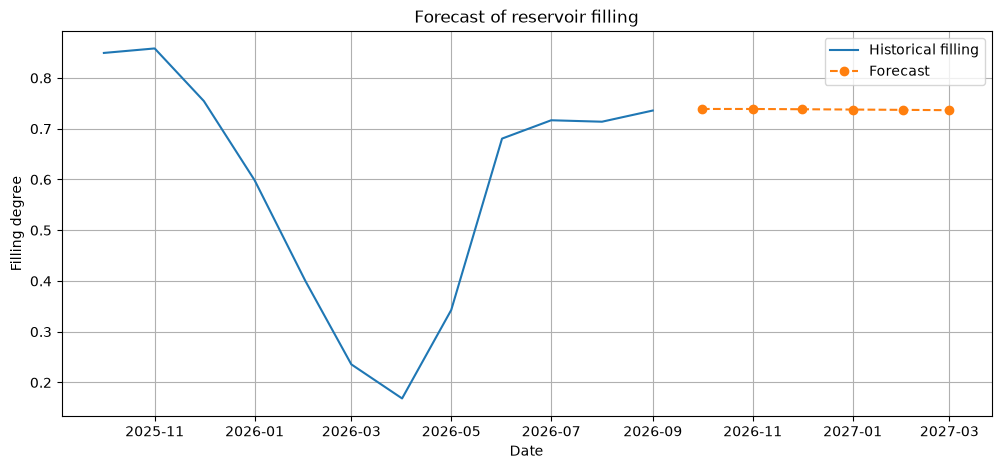

In [82]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    train_data.index,
    train_data["fyllingsgrad"],
    label="Historical filling",
)

plt.plot(
    forecast.index,
    forecast,
    label="Forecast",
    linestyle="--",
    marker="o",
)

plt.title("Forecast of reservoir filling")
plt.xlabel("Date")
plt.ylabel("Filling degree")
plt.legend()
plt.grid()

plt.show()